In [ ]:
import boto3, sagemaker

BUCKET = "used-cars-ha"       
PREFIX = "data"

sess   = sagemaker.Session()
region = sess.boto_region_name
role   = sagemaker.get_execution_role()

print("region:", region)
print("role  :", role)

s3 = boto3.client("s3")
for f in ["train/train.csv", "test/test.csv", "inference/test_features.csv"]:
    r = s3.head_object(Bucket=BUCKET, Key=f"{PREFIX}/{f}")
    print(f"OK  {f}  {r['ContentLength']:,} bytes")

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/ec2-user/.config/sagemaker/config.yaml


/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/__init__.py:86: SageMakerV2DeprecationWarning: You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation()
You are using the SageMaker Python SDK v2, which is on path of deprecation. v3 is the actively developed major version.
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.


region: eu-north-1
role  : arn:aws:iam::481719141347:role/service-role/AmazonSageMaker-ExecutionRole-20260805T185648
OK  train/train.csv  1,131,630 bytes
OK  test/test.csv  283,069 bytes
OK  inference/test_features.csv  278,604 bytes


## Step 2 — Retrieve the XGBoost Container
SageMaker's built-in XGBoost ships as a Docker image in ECR. `image_uris.retrieve` returns the correct image for our region automatically.

In [ ]:
from sagemaker import image_uris
# We have three options own container, custom scripts and pre-built containers. Here we will use a pre-built container for XGBoost.
xgb_image = image_uris.retrieve("xgboost", region, version="1.7-1")
print(xgb_image)

662702820516.dkr.ecr.eu-north-1.amazonaws.com/sagemaker-xgboost:1.7-1


## Step 3 — Configure the Training Job
Point XGBoost at the S3 training data and run with default hyperparameters.

In [ ]:
from sagemaker.estimator import Estimator
from sagemaker.inputs import TrainingInput

s3_train  = f"s3://{BUCKET}/{PREFIX}/train/"         
s3_output = f"s3://{BUCKET}/model"
# This uses the SDK v2 Estimator. SDK v3 replaces it with ModelTrainer
# (from sagemaker.train), which splits config into explicit objects — Compute for
# instance type/count, OutputDataConfig for the S3 path — instead of Estimator's
# flat argument list. Same training job underneath; v3 is just more modular.
est = Estimator(
    image_uri         = xgb_image,
    role              = role,
    instance_count    = 1,
    instance_type     = "ml.m5.large",   # separate managed training instance
    output_path       = s3_output,
    sagemaker_session = sess,
    base_job_name     = "usedcar-xgb",
)
#In a full production pipeline, we wouldn't hardcode 100. We would use Validation Sets with Early Stopping.
#  We’d set num_round=1000, but tell SageMaker to stop training automatically if the validation error stops improving 
# for 10 consecutive rounds. That guarantees peak performance without wasting compute or overfitting.

est.set_hyperparameters(objective="reg:squarederror", num_round=100)

train_input = TrainingInput(s3_train, content_type="text/csv")
print("training data:", s3_train)

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/estimator.py:588: SageMakerV2DeprecationWarning: Estimator is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelTrainer` (`from sagemaker.train import ModelTrainer`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
Estimator is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelTrainer` (`from sagemaker.train import ModelTrainer`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.


training data: s3://used-cars-ha/data/train/


## Step 4 — Run the Training Job
This launches a separate managed instance that trains, writes the model to S3, and terminates itself.

In [4]:
est.fit({"train": train_input})

INFO:sagemaker:Creating training-job with name: usedcar-xgb-2026-08-05-14-30-06-605


2026-08-05 14:30:06 Starting - Starting the training job...
2026-08-05 14:30:28 Starting - Preparing the instances for training...
2026-08-05 14:30:50 Downloading - Downloading input data...
2026-08-05 14:31:35 Downloading - Downloading the training image......../miniconda3/lib/python3.9/site-packages/sagemaker_containers/_server.py:22: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
[2026-08-05 14:32:50.073 ip-10-0-201-96.eu-north-1.compute.internal:7 INFO utils.py:28] RULE_JOB_STOP_SIGNAL_FILENAME: None
[2026-08-05 14:32:50.145 ip-10-0-201-96.eu-north-1.compute.internal:7 INFO profiler_config_parser.py:111] User has disabled profiler.
[2026-08-05:14:32:50:INFO] Imported framework sagemaker_xgboost_container.training
[2026-08-05:14:32:50:INFO] Failed to parse hyperparamet

## Step 5 — Evaluate with Batch Transform (No Endpoint)
The task forbids a real-time endpoint. Batch Transform launches an instance, scores the whole test file to S3, then auto-terminates. We feed `test_features.csv` (no labels) so the model never sees the answers.

In [5]:
transformer = est.transformer(
    instance_count = 1,
    instance_type  = "ml.m5.large",
    output_path    = f"s3://{BUCKET}/batch-out",
    assemble_with  = "Line",
    accept         = "text/csv",
)

transformer.transform(
    f"s3://{BUCKET}/{PREFIX}/inference/test_features.csv",
    content_type = "text/csv",
    split_type   = "Line",
)
transformer.wait()
print("predictions written to:", transformer.output_path)

/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/model.py:347: SageMakerV2DeprecationWarning: Model is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `ModelBuilder` (`from sagemaker.serve import ModelBuilder`).
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
  warn_v2_deprecation(
See https://github.com/aws/sagemaker-python-sdk/blob/master/migration.md for the migration guide. Set SAGEMAKER_SUPPRESS_V2_WARNING=1 to silence this warning.
INFO:sagemaker:Creating model with name: usedcar-xgb-2026-08-05-14-43-47-160
/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/sagemaker/transformer.py:115: SageMakerV2DeprecationWarning: Transformer is part of the SageMaker Python SDK v2, which is on path of deprecation. In v3, use `sagemaker.core.shapes.TransformJob`.
See https://github.com/aws/sagemaker-python-sdk

................................../miniconda3/lib/python3.9/site-packages/sagemaker_containers/_server.py:22: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
[2026-08-05:14:49:24:INFO] No GPUs detected (normal if no gpus installed)
[2026-08-05:14:49:24:INFO] No GPUs detected (normal if no gpus installed)
[2026-08-05:14:49:24:INFO] nginx config: 
worker_processes auto;
daemon off;
pid /tmp/nginx.pid;
error_log  /dev/stderr;
worker_rlimit_nofile 4096;
events {
  worker_connections 2048;
}
http {
  include /etc/nginx/mime.types;
  default_type application/octet-stream;
  access_log /dev/stdout combined;
  upstream gunicorn {
    server unix:/tmp/gunicorn.sock;
  }
  server {
    listen 8080 deferred;
    client_max_body_size 0;
    keepalive_timeout 3;
    location ~ ^/(ping|

## Step 6 — Compute Test Metrics
Download the predictions and the true labels, then compare. RMSE, MAE and R² each answer a different question.

In [7]:
import numpy as np, pandas as pd

s3 = boto3.client("s3")
s3.download_file(BUCKET, "batch-out/test_features.csv.out", "preds.csv")
s3.download_file(BUCKET, f"{PREFIX}/test/test.csv", "test_local.csv")

y_pred = pd.read_csv("preds.csv",      header=None)[0].values
y_true = pd.read_csv("test_local.csv", header=None)[0].values   # label = column 0

assert len(y_pred) == len(y_true), f"length mismatch: {len(y_pred)} vs {len(y_true)}"

err  = y_true - y_pred
rmse = np.sqrt(np.mean(err**2))                                  # root mean squared error
mae  = np.mean(np.abs(err))                                      # mean absolute error
r2   = 1 - np.sum(err**2) / np.sum((y_true - y_true.mean())**2)   # 1 - SSE/SST

print(f"rows evaluated : {len(y_true)}")
print(f"Test RMSE      : ${rmse:,.0f}")
print(f"Test MAE       : ${mae:,.0f}")
print(f"Test R²        : {r2:.4f}")
print(f"train RMSE was : $3,857   (gap = overfitting)")

rows evaluated : 758
Test RMSE      : $8,443
Test MAE       : $5,799
Test R²        : 0.8558
train RMSE was : $3,857   (gap = overfitting)


In [8]:
print("Model artifact:", est.model_data)
print("Predictions   :", transformer.output_path)
print("\nTraining instance : auto-terminated")
print("Transform instance: auto-terminated")
print("Real-time endpoint: never created")
print("Notebook instance : STOP IT NOW in the console")

Model artifact: s3://used-cars-ha/model/usedcar-xgb-2026-08-05-14-30-06-605/output/model.tar.gz
Predictions   : s3://used-cars-ha/batch-out

Training instance : auto-terminated
Transform instance: auto-terminated
Real-time endpoint: never created
Notebook instance : STOP IT NOW in the console


## Step 11 — Visualize Model Results
Predictions from the SageMaker Batch Transform job (`batch-out/`). Three views: predicted vs actual, error distribution, and comparison against a baseline that always predicts the mean.

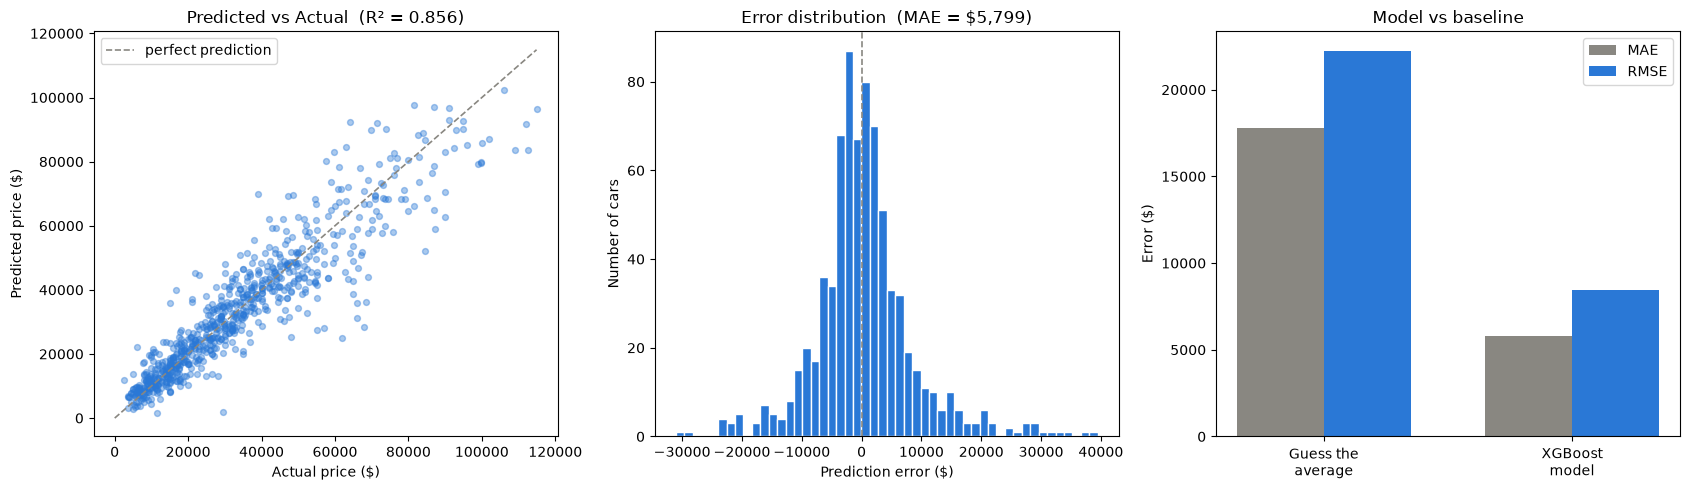

RMSE $8,443 | MAE $5,799 | R² 0.8558
baseline RMSE $22,252 | baseline MAE $17,775
improvement: 62% RMSE, 67% MAE


: 

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
 
y_pred   = pd.read_csv("preds.csv", header=None)[0].values
y_true   = pd.read_csv("test.csv",  header=None)[0].values   # local, from Part A
baseline = pd.read_csv("train.csv", header=None)[0].mean()   # local, from Part A

err  = y_true - y_pred
rmse = np.sqrt(np.mean(err**2)); mae = np.mean(np.abs(err))
r2   = 1 - np.sum(err**2)/np.sum((y_true-y_true.mean())**2)
b_rmse = np.sqrt(np.mean((y_true-baseline)**2))
b_mae  = np.mean(np.abs(y_true-baseline))

fig, ax = plt.subplots(1, 3, figsize=(17,5))

ax[0].scatter(y_true, y_pred, alpha=0.4, s=18, color="#2a78d6")
lims = [0, max(y_true.max(), y_pred.max())]
ax[0].plot(lims, lims, "--", color="#898781", lw=1.2, label="perfect prediction")
ax[0].set_xlabel("Actual price ($)"); ax[0].set_ylabel("Predicted price ($)")
ax[0].set_title(f"Predicted vs Actual  (R² = {r2:.3f})"); ax[0].legend()

ax[1].hist(err, bins=50, color="#2a78d6", edgecolor="white")
ax[1].axvline(0, color="#898781", ls="--", lw=1.2)
ax[1].set_xlabel("Prediction error ($)"); ax[1].set_ylabel("Number of cars")
ax[1].set_title(f"Error distribution  (MAE = ${mae:,.0f})")

x = np.arange(2); w = 0.35
ax[2].bar(x-w/2, [b_mae, mae],   w, label="MAE",  color="#898781")
ax[2].bar(x+w/2, [b_rmse, rmse], w, label="RMSE", color="#2a78d6")
ax[2].set_xticks(x); ax[2].set_xticklabels(["Guess the\naverage", "XGBoost\nmodel"])
ax[2].set_ylabel("Error ($)"); ax[2].set_title("Model vs baseline"); ax[2].legend()

plt.tight_layout(); plt.savefig("results.png", dpi=120); plt.show()

print(f"RMSE ${rmse:,.0f} | MAE ${mae:,.0f} | R² {r2:.4f}")
print(f"baseline RMSE ${b_rmse:,.0f} | baseline MAE ${b_mae:,.0f}")
print(f"improvement: {(1-rmse/b_rmse)*100:.0f}% RMSE, {(1-mae/b_mae)*100:.0f}% MAE")